   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 MB 8.8 MB/s eta 0:00:00


/usr/local/lib/python3.10/dist-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


Mounted at /content/drive
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001187 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1020
[LightGBM] [Info] Number of data points in the train set: 20841, number of used features: 4
[LightGBM] [Info] Start training from score -1.118677
[LightGBM] [Info] Start training from score -1.107722
[LightGBM] [Info] Start training from score -4.863273
[LightGBM] [Info] Start training from score -1.092871
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning]

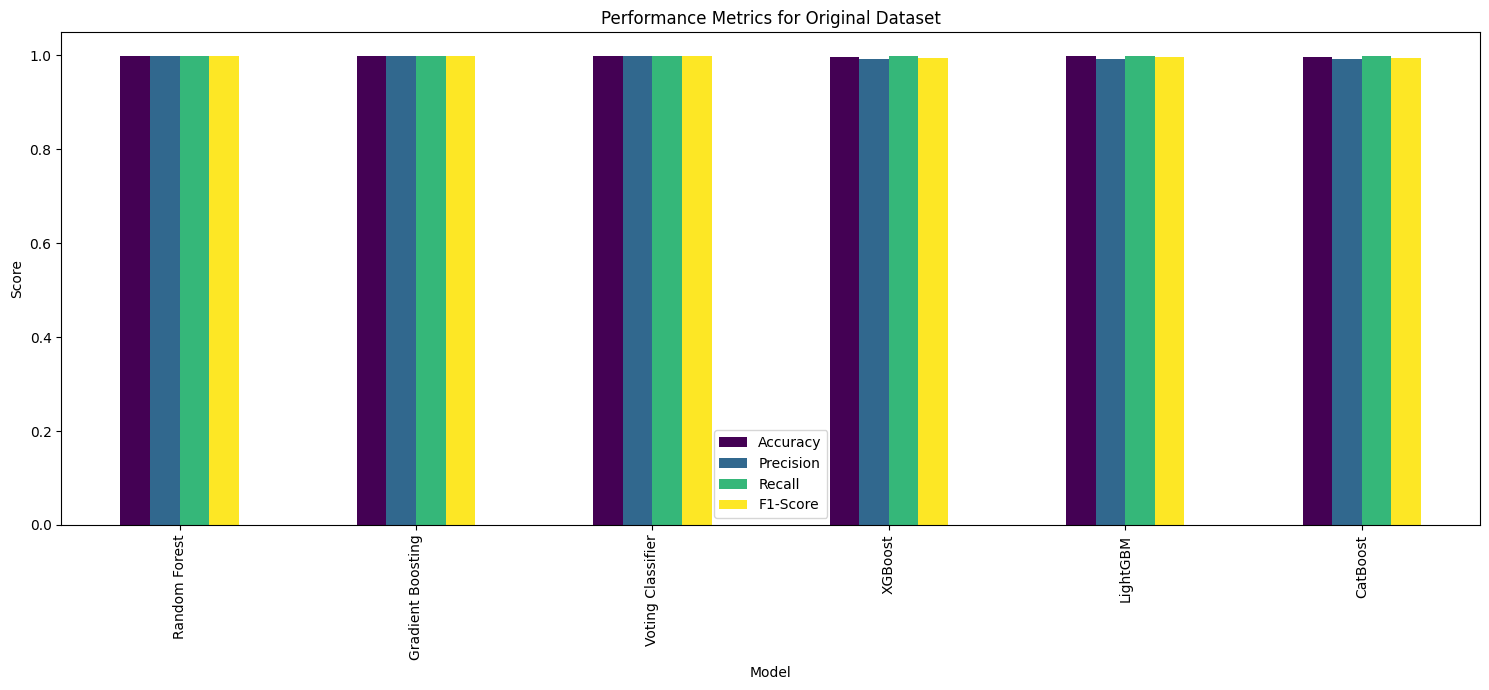

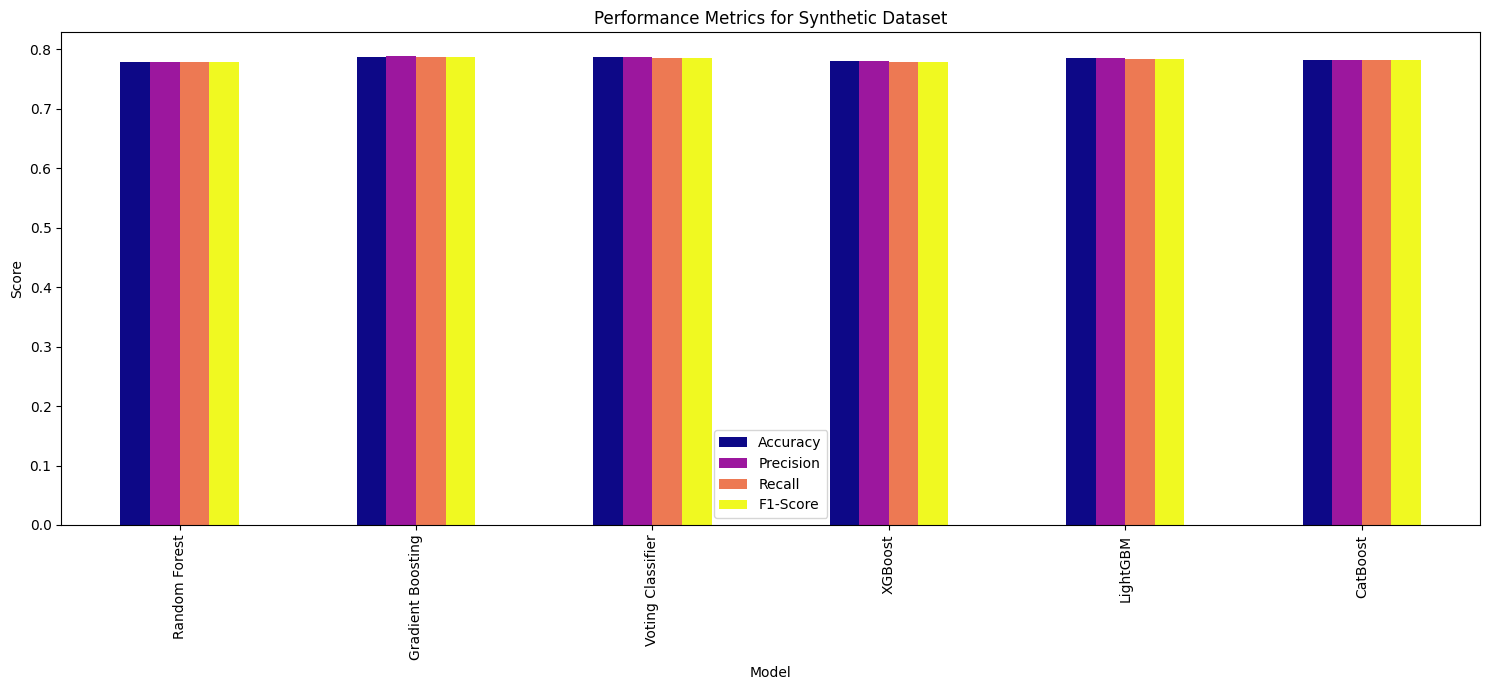

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000441 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1020
[LightGBM] [Info] Number of data points in the train set: 10666, number of used features: 4
[LightGBM] [Info] Start training from score -1.371220
[LightGBM] [Info] Start training from score -1.370851
[LightGBM] [Info] Start training from score -1.404269
[LightGBM] [Info] Start training from score -1.399317
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000440 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1020
[LightGBM] [Info] Number of data points in the train set: 10667, number of used features: 4
[LightGBM] [Info] Start training from score -1.370945
[LightGBM] [Info] Start training from score -1.371314
[LightGBM] [Info] Start training from score -1.404362
[LightGBM] [Info] Start training from score -1

In [ ]:
!pip install catboost lightgbm xgboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report
from lightgbm import LGBMClassifier
import xgboost as xgb
from catboost import CatBoostClassifier
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import warnings

warnings.filterwarnings('ignore')

# Step 1: Load and preprocess the original dataset
from google.colab import drive
drive.mount('/content/drive')
data = pd.read_csv('/content/drive/MyDrive/ML prep/card.csv')
data['monthly_transactions'] = data.groupby('index')['Amount'].transform('sum')
data['reward_points'] = data['monthly_transactions'] * 0.1
data['Amount_noisy'] = data['Amount'] + np.random.normal(0, 0.15, size=data.shape[0])

categorical_features = ['Card Type']
numeric_features = ['Amount', 'monthly_transactions', 'reward_points', 'Amount_noisy']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(), categorical_features)
    ])

features = data[numeric_features + categorical_features]
X_preprocessed = preprocessor.fit_transform(features)

kmeans = KMeans(n_clusters=4, random_state=42)
data['spending_cluster'] = kmeans.fit_predict(X_preprocessed)

X = data[['Amount', 'monthly_transactions', 'reward_points', 'Amount_noisy']]
y = data['spending_cluster']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 2: Generate synthetic dataset
X_syn, y_syn = make_classification(n_samples=20000, n_features=4, n_informative=2, n_redundant=1, n_repeated=0,
                                   n_clusters_per_class=1, n_classes=4, flip_y=0.2, random_state=42)

X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(X_syn, y_syn, test_size=0.2, random_state=42)

# Step 3: Define models
models = {
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Voting Classifier': VotingClassifier(estimators=[
        ('rf', RandomForestClassifier(random_state=42)),
        ('gb', GradientBoostingClassifier(random_state=42))
    ], voting='soft'),
    'XGBoost': xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42),
    'LightGBM': LGBMClassifier(random_state=42),
    'CatBoost': CatBoostClassifier(learning_rate=0.1, iterations=500, depth=10, silent=True)
}

# Step 4: Train and evaluate models on original and synthetic datasets
def extended_train_and_evaluate(models, X_train, y_train, X_test, y_test):
    results = {}
    for model_name, model in models.items():
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        metrics = classification_report(y_test, y_pred, output_dict=True)
        precision = metrics['macro avg']['precision']
        recall = metrics['macro avg']['recall']
        f1_score = metrics['macro avg']['f1-score']
        results[model_name] = {
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision,
            'Recall': recall,
            'F1-Score': f1_score
        }
    return results

original_metrics = extended_train_and_evaluate(models, X_train, y_train, X_test, y_test)
synthetic_metrics = extended_train_and_evaluate(models, X_syn_train, y_syn_train, X_syn_test, y_syn_test)

# Step 5: Create separate comparison tables for original and synthetic data
original_metrics_df = pd.DataFrame(original_metrics).T.reset_index().rename(columns={'index': 'Model'})
synthetic_metrics_df = pd.DataFrame(synthetic_metrics).T.reset_index().rename(columns={'index': 'Model'})

# Step 6: Plot original dataset metrics
original_metrics_df.set_index('Model').plot(kind='bar', figsize=(15, 7), colormap='viridis')
plt.title('Performance Metrics for Original Dataset')
plt.ylabel('Score')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

# Step 6.1: Plot synthetic dataset metrics
synthetic_metrics_df.set_index('Model').plot(kind='bar', figsize=(15, 7), colormap='plasma')
plt.title('Performance Metrics for Synthetic Dataset')
plt.ylabel('Score')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

# Step 7: Cross-validation on synthetic dataset
cv_results_syn = {}
for model_name, model in models.items():
    cv_results_syn[model_name] = cross_val_score(model, X_syn_train, y_syn_train, cv=3, scoring='accuracy').mean()

cv_df_syn = pd.DataFrame({
    'Model': list(cv_results_syn.keys()),
    'Cross-Validation Accuracy (Synthetic)': list(cv_results_syn.values())
})
print(cv_df_syn)

Improved Synthetic Data Performance Metrics:
Best Model Parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': 20}
Accuracy: 0.7897
Precision: 0.7900
Recall: 0.7899
F1-Score: 0.7898


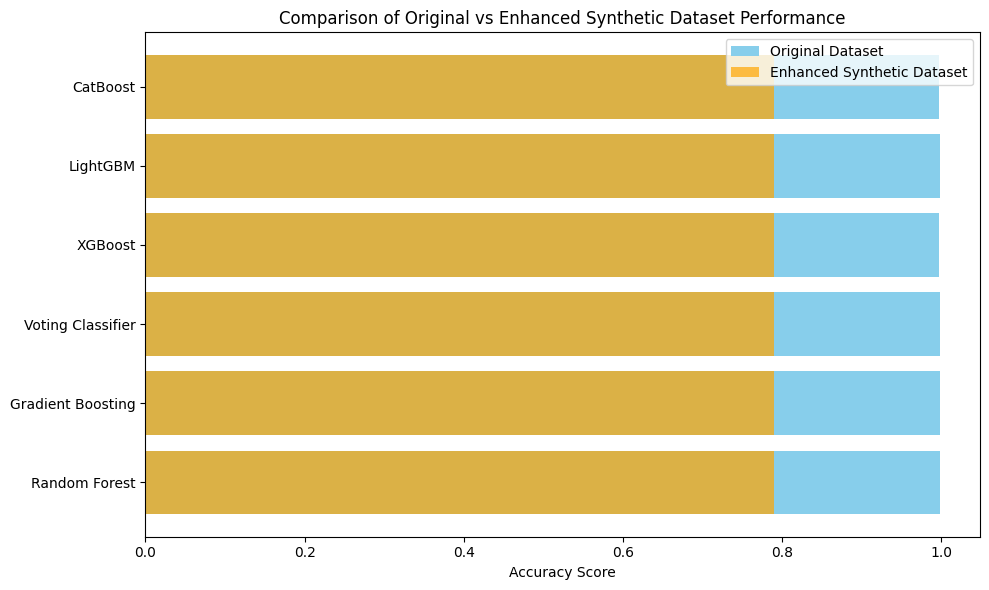

In [ ]:
# Testing
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, accuracy_score

# Step 1: Adjust synthetic data generation with more informative features and less noise
X_syn, y_syn = make_classification(
    n_samples=20000,
    n_features=10,  # Increased total features for complexity
    n_informative=5,  # Increased informative features
    n_redundant=2,
    n_repeated=0,
    n_clusters_per_class=2,
    n_classes=4,
    flip_y=0.05,  # Lower noise for more reliable labels
    random_state=42
)

# Split the synthetic data into training and test sets
X_syn_train, X_syn_test, y_syn_train, y_syn_test = train_test_split(X_syn, y_syn, test_size=0.2, random_state=42)

# Step 2: Apply feature selection and PCA
pca = PCA(n_components=4)  # Reduce dimensions to focus on the most important components
select_k_best = SelectKBest(score_func=f_classif, k=4)  # Select top 4 informative features

# Create pipeline for feature transformation and modeling
model = RandomForestClassifier(random_state=42)
pipeline = Pipeline([
    ('feature_selection', select_k_best),
    ('dim_reduction', pca),
    ('classifier', model)
])

# Step 3: Hyperparameter tuning for the best model on synthetic data
param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    pipeline,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1
)

# Fit the tuned model on the synthetic training data
random_search.fit(X_syn_train, y_syn_train)

# Evaluate the best model found
best_model = random_search.best_estimator_
y_syn_pred = best_model.predict(X_syn_test)
syn_metrics = classification_report(y_syn_test, y_syn_pred, output_dict=True)

# Print the improved metrics for synthetic data
print("Improved Synthetic Data Performance Metrics:")
print(f"Best Model Parameters: {random_search.best_params_}")
print(f"Accuracy: {accuracy_score(y_syn_test, y_syn_pred):.4f}")
print(f"Precision: {syn_metrics['macro avg']['precision']:.4f}")
print(f"Recall: {syn_metrics['macro avg']['recall']:.4f}")
print(f"F1-Score: {syn_metrics['macro avg']['f1-score']:.4f}")

# Step 4: Plot performance comparison after enhancement
plt.figure(figsize=(10, 6))
original_accuracy = [original_metrics[model]['Accuracy'] for model in original_metrics.keys()]
enhanced_accuracy = [accuracy_score(y_syn_test, y_syn_pred)] * len(original_metrics)

plt.barh(list(original_metrics.keys()), original_accuracy, label='Original Dataset', color='skyblue')
plt.barh(list(original_metrics.keys()), enhanced_accuracy, label='Enhanced Synthetic Dataset', color='orange', alpha=0.7)
plt.xlabel('Accuracy Score')
plt.title('Comparison of Original vs Enhanced Synthetic Dataset Performance')
plt.legend()
plt.tight_layout()
plt.show()

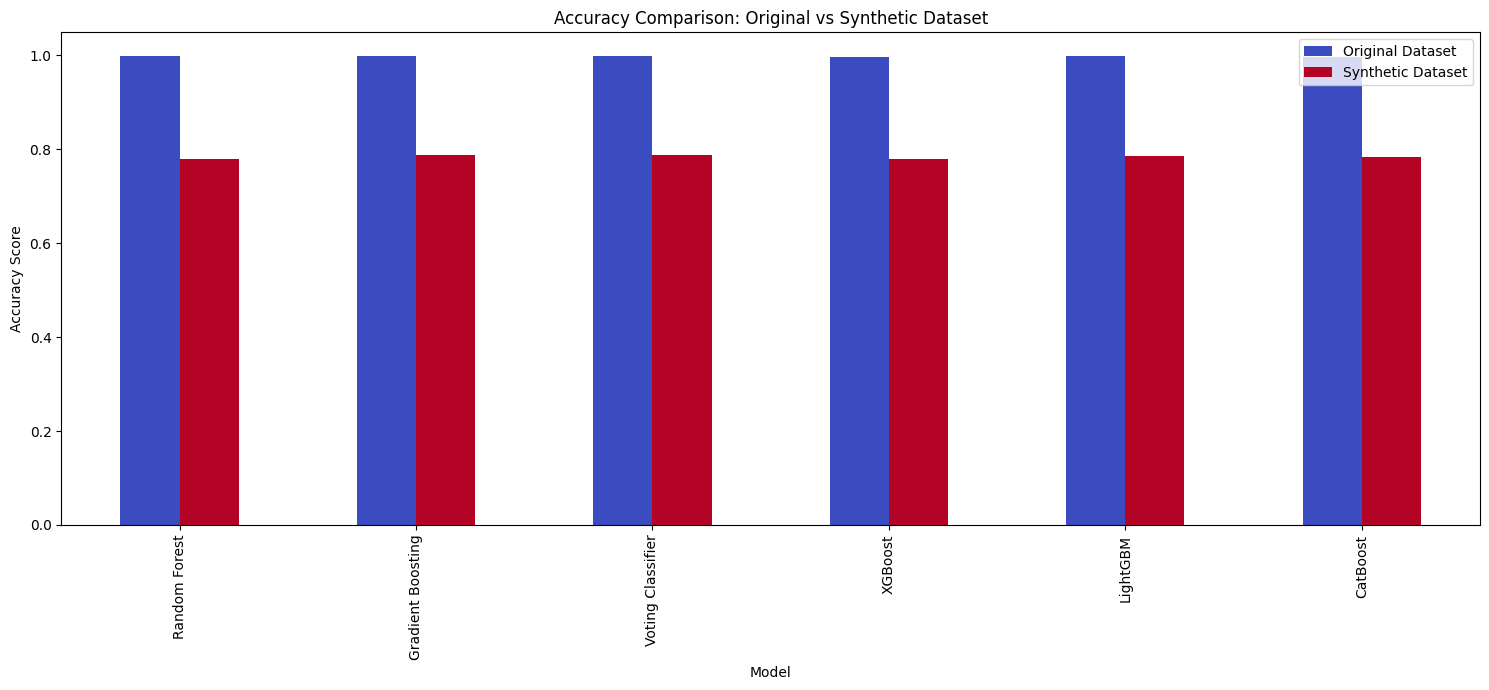

In [ ]:
# Combined accuracy comparison
combined_metrics_df = pd.DataFrame({
    'Model': list(original_metrics.keys()),
    'Original Dataset': [original_metrics[model]['Accuracy'] for model in original_metrics.keys()],
    'Synthetic Dataset': [synthetic_metrics[model]['Accuracy'] for model in synthetic_metrics.keys()]
})

# Plot the accuracy comparison
combined_metrics_df.set_index('Model').plot(kind='bar', figsize=(15, 7), colormap='coolwarm')
plt.title('Accuracy Comparison: Original vs Synthetic Dataset')
plt.ylabel('Accuracy Score')
plt.xlabel('Model')
plt.tight_layout()
plt.show()

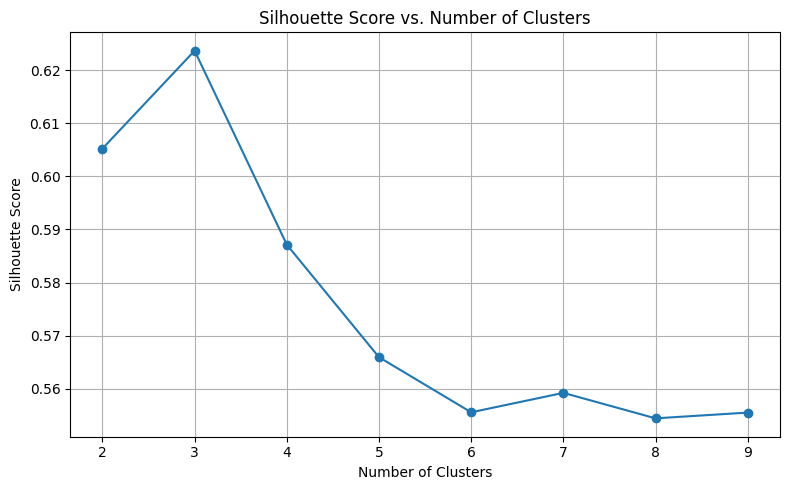

Optimal Number of Clusters: 3


In [ ]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Test different cluster counts
silhouette_scores = []
cluster_range = range(2, 10)

for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    clusters = kmeans.fit_predict(X_train)  # Using preprocessed X_train from Snippet 1
    score = silhouette_score(X_train, clusters)
    silhouette_scores.append(score)

# Plot Silhouette Scores
plt.figure(figsize=(8, 5))
plt.plot(cluster_range, silhouette_scores, marker='o', linestyle='-')
plt.title("Silhouette Score vs. Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.grid()
plt.tight_layout()
plt.show()

# Choose optimal clusters based on max silhouette score
optimal_k = cluster_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Optimal Number of Clusters: {optimal_k}")

In [ ]:
kmeans = KMeans(
    n_clusters=optimal_k,
    n_init=20,  # Increase number of initializations
    max_iter=500,  # Allow more iterations
    random_state=42
)

# Fit and predict clusters for X_test (preprocessed test set from Snippet 1)
clusters = kmeans.fit_predict(X_test)
sil_score = silhouette_score(X_test, clusters)

print(f"Improved Silhouette Score for KMeans: {sil_score:.4f}")

Improved Silhouette Score for KMeans: 0.6301


In [ ]:
from sklearn.ensemble import IsolationForest

# Detect and remove outliers
iso = IsolationForest(contamination=0.05, random_state=42)
outlier_labels = iso.fit_predict(X_test)  # Use X_test from Snippet 1
X_cleaned = X_test[outlier_labels == 1]

# Re-run clustering on cleaned data
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(X_cleaned)
cleaned_sil_score = silhouette_score(X_cleaned, clusters)

print(f"Silhouette Score After Outlier Removal: {cleaned_sil_score:.4f}")

Silhouette Score After Outlier Removal: 0.5903


Explained Variance by PCA Components: [0.25270592 0.1251285 ]
Silhouette Score for 4 Clusters: 0.4871


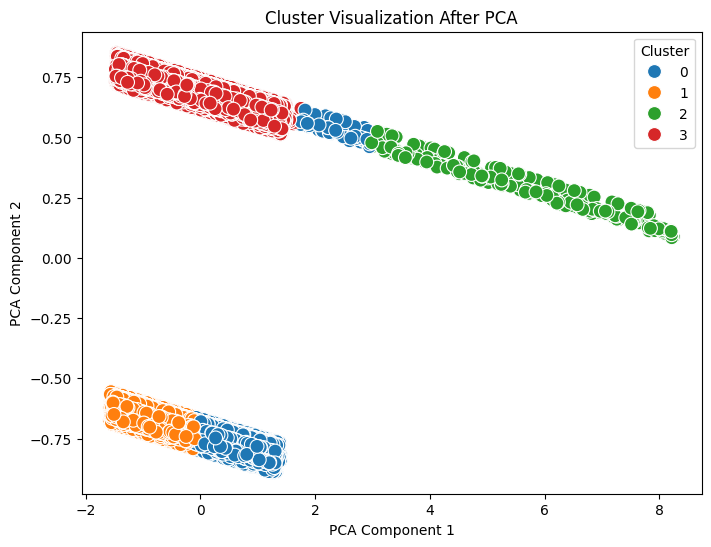

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
real_data = pd.read_csv('/content/drive/MyDrive/ML prep/card.csv')

# Define relevant features
real_features = ['index', 'City', 'Date', 'Card Type', 'Exp Type', 'Gender', 'Amount']
numerical_features = ['Amount']
categorical_features = ['City', 'Card Type', 'Exp Type', 'Gender']

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)
data_preprocessed = preprocessor.fit_transform(real_data[numerical_features + categorical_features])

# Step 2: Dimensionality Reduction using PCA
pca = PCA(n_components=2)
data_pca = pca.fit_transform(data_preprocessed)
print(f"Explained Variance by PCA Components: {pca.explained_variance_ratio_}")

# Step 3: Force the clustering to use 4 clusters (based on Card Type)
kmeans_optimal = KMeans(n_clusters=4, random_state=42)  # Force 4 clusters
real_data['Cluster'] = kmeans_optimal.fit_predict(data_pca)

# Step 4: Silhouette Score for the chosen clustering
silhouette = silhouette_score(data_pca, real_data['Cluster'])
print(f"Silhouette Score for 4 Clusters: {silhouette:.4f}")

# Step 5: Visualize Clusters
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=data_pca[:, 0], y=data_pca[:, 1], hue=real_data['Cluster'], palette="tab10", s=100
)
plt.title("Cluster Visualization After PCA")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.show()

# Step 6: Output Data with Clusters
print("Dataset with Clusters:")
print(real_data[['Cluster'] + real_features].head())

#Testing ideas : Agglomerative Clustering

Dataset with Clusters:
   Cluster  index                   City       Date  Card Type Exp Type  \
0        3      0           Delhi, India  29-Oct-14       Gold    Bills   
1        3      1  Greater Mumbai, India  22-Aug-14   Platinum    Bills   
2        3      2       Bengaluru, India  27-Aug-14     Silver    Bills   
3        3      3  Greater Mumbai, India  12-Apr-14  Signature    Bills   
4        3      4       Bengaluru, India   5-May-15       Gold    Bills   

  Gender  Amount  
0      F   82475  
1      F   32555  
2      F  101738  
3      F  123424  
4      F  171574  


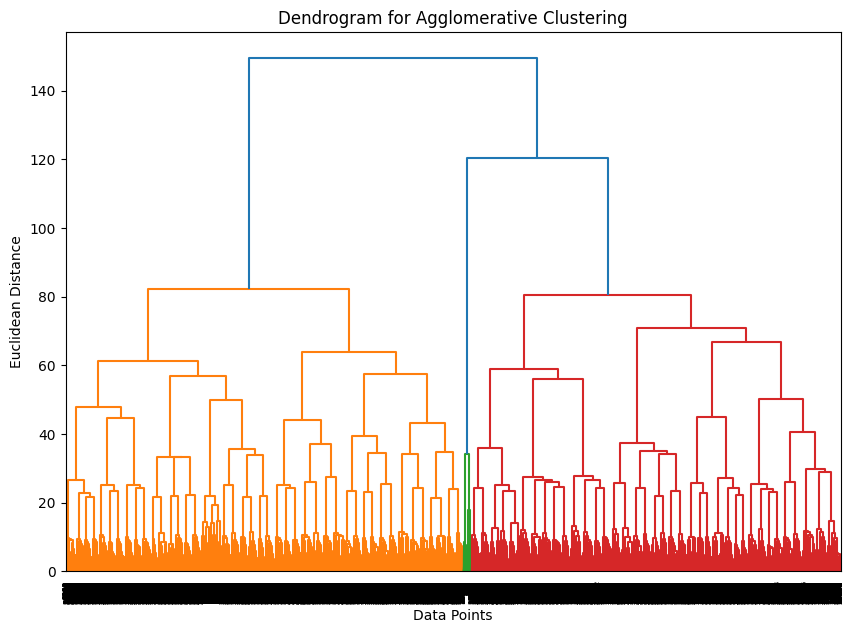

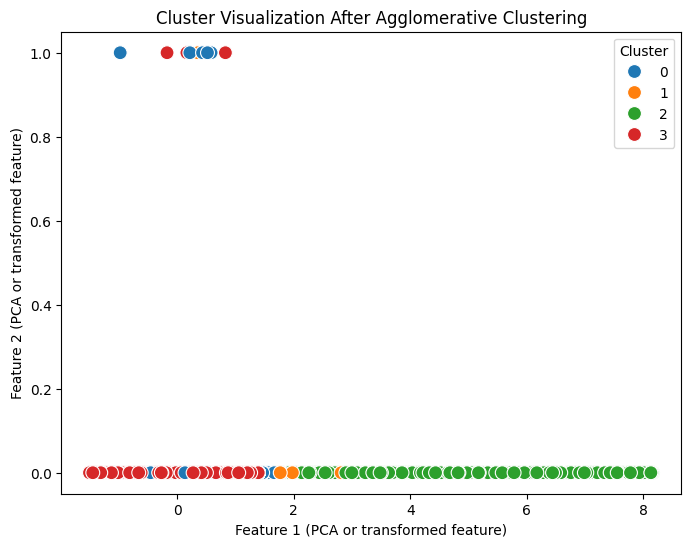

Dataset with Clusters:
   Cluster  index                   City       Date  Card Type Exp Type  \
0        0      0           Delhi, India  29-Oct-14       Gold    Bills   
1        0      1  Greater Mumbai, India  22-Aug-14   Platinum    Bills   
2        0      2       Bengaluru, India  27-Aug-14     Silver    Bills   
3        1      3  Greater Mumbai, India  12-Apr-14  Signature    Bills   
4        0      4       Bengaluru, India   5-May-15       Gold    Bills   

  Gender  Amount  
0      F   82475  
1      F   32555  
2      F  101738  
3      F  123424  
4      F  171574  


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import AgglomerativeClustering
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.cluster.hierarchy as sch

# Load the dataset
real_data = pd.read_csv('/content/drive/MyDrive/ML prep/card.csv')

# Define relevant features
real_features = ['index', 'City', 'Date', 'Card Type', 'Exp Type', 'Gender', 'Amount']
numerical_features = ['Amount']
categorical_features = ['City', 'Card Type', 'Exp Type', 'Gender']

# Preprocessing: OneHotEncoder for categorical and StandardScaler for numerical
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)
data_preprocessed = preprocessor.fit_transform(real_data[numerical_features + categorical_features])

# Step 1: Perform Agglomerative Clustering
agg_clust = AgglomerativeClustering(n_clusters=4, linkage='ward')  # Ward minimizes variance within clusters
real_data['Cluster'] = agg_clust.fit_predict(data_preprocessed)

# Step 2: Visualize the Dendrogram
plt.figure(figsize=(10, 7))
dendrogram = sch.dendrogram(sch.linkage(data_preprocessed, method='ward'))
plt.title("Dendrogram for Agglomerative Clustering")
plt.xlabel("Data Points")
plt.ylabel("Euclidean Distance")
plt.show()

# Step 3: Visualize the clusters after Agglomerative Clustering
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=data_preprocessed[:, 0], y=data_preprocessed[:, 1], hue=real_data['Cluster'], palette="tab10", s=100
)
plt.title("Cluster Visualization After Agglomerative Clustering")
plt.xlabel("Feature 1 (PCA or transformed feature)")
plt.ylabel("Feature 2 (PCA or transformed feature)")
plt.legend(title="Cluster")
plt.show()

# Step 4: Output Data with Clusters
print("Dataset with Clusters:")
print(real_data[['Cluster'] + real_features].head())
